# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal para clasificación de imágenes usando **Keras 3**.

En este ejercicio aplicarás **la misma receta** sobre un dataset diferente: **CIFAR-10 convertido a escala de grises**.

No necesitas diseñar un pipeline nuevo. La descarga, conversión a escala de grises y visualización están resueltas. Tu trabajo es completar únicamente las etapas de Keras que vimos en clase:

```text
Datos → Normalización → Modelo → Loss + Optimizer → fit() → evaluate() → Predicción
```

Las celdas marcadas con `# TODO` son las que debes completar.


---
## 0. Librerías


In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framewo

---
# 1. Dataset: CIFAR-10

CIFAR-10 contiene 50,000 imágenes de entrenamiento y 10,000 de prueba. Las imágenes originales son de **32×32×3** y pertenecen a 10 categorías:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.


In [2]:
# Esta parte está resuelta.
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

y_train = y_train.squeeze()
y_test = y_test.squeeze()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train original:", X_train.shape)
print("X_test original :", X_test.shape)
print("y_train         :", y_train.shape)


X_train original: (50000, 32, 32, 3)
X_test original : (10000, 32, 32, 3)
y_train         : (50000,)


## 1.1 RGB → escala de grises

Usaremos la transformación:

$$Gray = 0.299R + 0.587G + 0.114B$$

Esta parte está resuelta porque el objetivo del ejercicio es practicar Keras.


In [3]:
X_train = (
    0.299 * X_train[..., 0] +
    0.587 * X_train[..., 1] +
    0.114 * X_train[..., 2]
)

X_test = (
    0.299 * X_test[..., 0] +
    0.587 * X_test[..., 1] +
    0.114 * X_test[..., 2]
)

print("X_train grayscale:", X_train.shape)
print("X_test grayscale :", X_test.shape)


X_train grayscale: (50000, 32, 32)
X_test grayscale : (10000, 32, 32)


### Pregunta 1

Despu?s de convertir las im?genes a escala de grises, cada imagen tiene tama?o `32?32`.

?Cu?ntos valores tendr? cada imagen despu?s de aplicar `Flatten()`?

**Respuesta:** 32 ? 32 = **1,024 valores**.


## 1.2 Normalización

Los valores de los píxeles están entre 0 y 255. Completa el código para llevarlos al rango `[0,1]`.


In [4]:
# TODO 1 ? Normalizaci?n
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())


0.0 1.0


In [5]:
# Validación TODO 1
assert X_train.dtype == np.float32
assert X_test.dtype == np.float32
assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
print("✓ Datos normalizados correctamente")


✓ Datos normalizados correctamente


## 1.3 Visualización

Esta parte está resuelta.


notebooks\lecture7\Challenge_Keras3_CIFAR10_Grayscale.ipynb:cell12:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


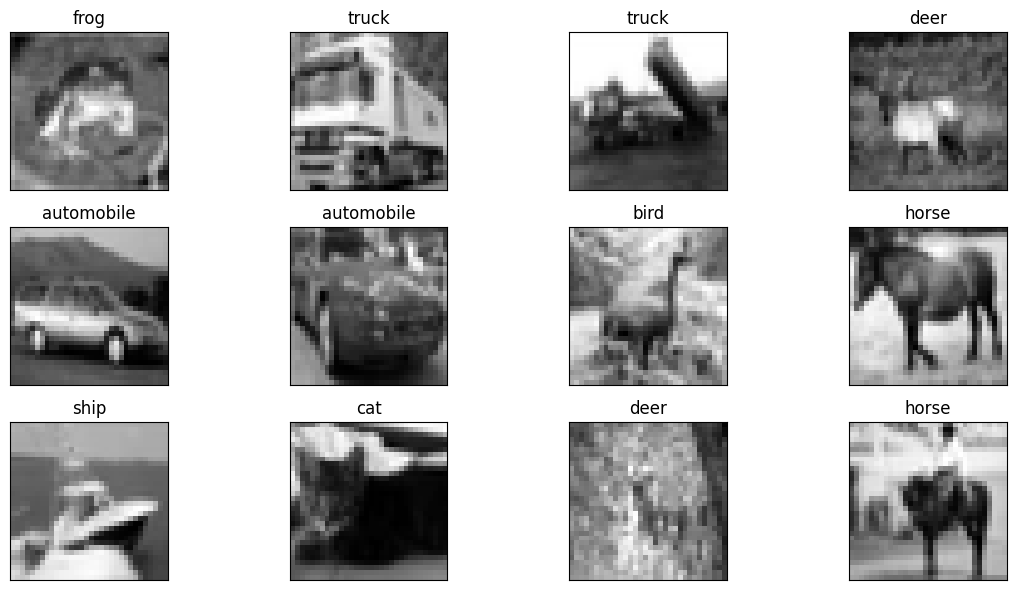

In [6]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Construiremos la misma arquitectura conceptual vista en clase:

```text
Imagen 32×32
   ↓
Flatten
   ↓
1024 valores
   ↓
Dense(128)
   ↓
ReLU
   ↓
Dense(10)
   ↓
Logits
```

> La última capa **no** debe tener Softmax. Trabajaremos con logits.


In [7]:
# TODO 2 ? Completa la arquitectura
model = keras.Sequential([
    keras.Input(shape=(32, 32)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)
])

model.summary()


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 132,490 (517.54 KB)
 Trainable params: 132,490 (517.54 KB)
 Non-trainable params: 0 (0.00 B)


In [8]:
# Validación TODO 2
expected_params = (1024 * 128 + 128) + (128 * 10 + 10)
assert model.count_params() == expected_params
print(f"✓ Arquitectura correcta: {model.count_params():,} parámetros")


✓ Arquitectura correcta: 132,490 parámetros


### Preguntas

**2.** ?Por qu? necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** `Dense` recibe un vector por ejemplo; `Flatten()` convierte la matriz 32?32 en un vector de 1,024 valores y conserva todos los p?xeles como entradas.

**3.** ?Por qu? la ?ltima capa tiene 10 neuronas?

**Respuesta:** CIFAR-10 tiene diez categor?as; cada neurona produce un logit para una clase.

**4.** ?Qu? funci?n cumple `ReLU`?

**Respuesta:** Introduce no linealidad al conservar valores positivos y convertir los negativos en cero, lo que permite aprender relaciones m?s complejas que una transformaci?n lineal.


---
# 3. Configurar el entrenamiento

Usaremos:

- `Adam`
- `SparseCategoricalCrossentropy`
- `accuracy`

Como la red produce logits, la pérdida debe configurarse con `from_logits=True`.


In [9]:
lr_rate = 0.001

# TODO 3 ? Configura el entrenamiento
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)


### Pregunta 5

?Por qu? usamos `from_logits=True`?

**Respuesta:** La ?ltima capa devuelve logits sin Softmax. `from_logits=True` indica a la p?rdida que convierta esos valores de forma num?ricamente estable al calcular la entrop?a cruzada.


---
# 4. Entrenar el modelo

Usaremos 10 épocas y mini-batches de 64 ejemplos. Completa `fit()`.


In [10]:
epochs = 10
batch_size = 64

# TODO 4 ? Entrenamiento
history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)


Epoch 1/10

  1/782 ━━━━━━━━━━━━━━━━━━━━ 10:37 816ms/step - accuracy: 0.0938 - loss: 2.4658
 30/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1286 - loss: 2.3204     
 56/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1504 - loss: 2.2564
 78/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1607 - loss: 2.2306
100/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1692 - loss: 2.2102
129/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1781 - loss: 2.1947
159/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1889 - loss: 2.1757
189/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1968 - loss: 2.1636
220/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2022 - loss: 2.1545
251/782 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2051 - loss: 2.1496
280/782 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2089 - loss: 2.1424
309/782 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2126 - loss: 2.1343
339/782 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2162 - loss: 2.1266
362

### Preguntas

**6.** ?Qu? representa una `epoch`?

**Respuesta:** Una pasada completa por todos los ejemplos del conjunto de entrenamiento.

**7.** ?Qu? representa `batch_size=64`?

**Respuesta:** El modelo procesa 64 ejemplos antes de calcular el gradiente y actualizar sus par?metros (salvo el ?ltimo lote, que puede ser menor).


## 4.1 Curvas de aprendizaje

Esta parte está resuelta.


notebooks\lecture7\Challenge_Keras3_CIFAR10_Grayscale.ipynb:cell24:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


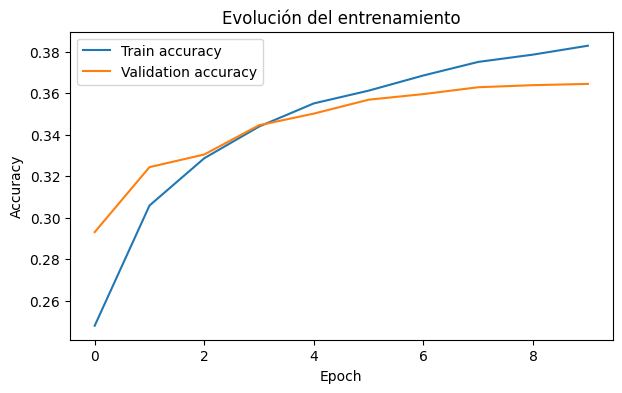

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.show()


### Pregunta 8

Observa las dos curvas. ?Hay evidencia de overfitting? Justifica brevemente.

**Respuesta:** Hay una brecha peque?a al final: accuracy de entrenamiento **38.28%** y de validaci?n **36.44%** (1.84 puntos porcentuales). No se observa evidencia fuerte de overfitting en estas 10 ?pocas; ambas curvas aumentan y se mantienen relativamente pr?ximas.


---
# 5. Evaluar el modelo

Completa `evaluate()`.


In [12]:
# TODO 5 ? Evaluaci?n
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 1.7828
Test accuracy : 0.3644
Accuracy (%)  : 36.44%


### Pregunta 9

Compara este resultado con Fashion-MNIST, utilizado en clase.

?CIFAR-10 en escala de grises parece m?s f?cil o m?s dif?cil para esta red? Justifica usando el accuracy obtenido.

**Respuesta:** El accuracy obtenido en CIFAR-10 en escala de grises es **36.44%**. Es razonable esperar que sea m?s dif?cil para esta red que Fashion-MNIST por la mayor variedad de objetos, fondos y formas, pero el notebook no incluye el accuracy de Fashion-MNIST de clase, as? que no puedo establecer una comparaci?n num?rica ni confirmarlo directamente con ese baseline.


---
# 6. Logits y Softmax

La salida de la red son 10 logits. Para interpretarlos como probabilidades necesitamos Softmax.


Logits:
[[ 1.0159081  -1.5197878   1.565548    0.19026011  1.2189476   0.24033228
   0.38828593  0.34409863 -0.18995267 -1.9548081 ]]


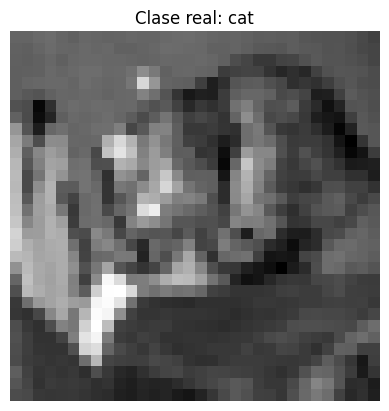

In [13]:
index = 0
image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Clase real: {class_names[true_class]}")
plt.axis("off")
plt.show()

image_batch = np.expand_dims(image, axis=0)
logits = model(image_batch, training=False)

print("Logits:")
print(keras.ops.convert_to_numpy(logits))


In [14]:
# TODO 6 ? Logits -> probabilidades
probabilities = keras.ops.softmax(logits)

# TODO 7 ? Clase con mayor probabilidad
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])

print("Clase real     :", class_names[true_class])
print("Clase predicha :", class_names[prediction])


Clase real     : cat
Clase predicha : bird


In [15]:
probabilities_np = keras.ops.convert_to_numpy(probabilities)[0]

print("\nProbabilidades:")
for i, p in enumerate(probabilities_np):
    marker = " ← predicción" if i == prediction else ""
    print(f"{class_names[i]:12s}: {p:.4f}{marker}")

print("\nSuma:", probabilities_np.sum())



Probabilidades:
airplane    : 0.1580
automobile  : 0.0125
bird        : 0.2737 ← predicción
cat         : 0.0692
deer        : 0.1935
dog         : 0.0727
frog        : 0.0843
horse       : 0.0807
ship        : 0.0473
truck       : 0.0081

Suma: 1.0000001


### Pregunta 10

?Por qu? las probabilidades producidas por `Softmax` deben sumar aproximadamente 1?

**Respuesta:** Softmax exponentia cada logit y divide cada exponencial por la suma de todas; as? cada salida es no negativa y la suma de las diez probabilidades es uno (con peque?as diferencias de redondeo).


---
# 7. Varias predicciones

Esta parte está resuelta. Observa especialmente los errores del modelo.


notebooks\lecture7\Challenge_Keras3_CIFAR10_Grayscale.ipynb:cell35:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


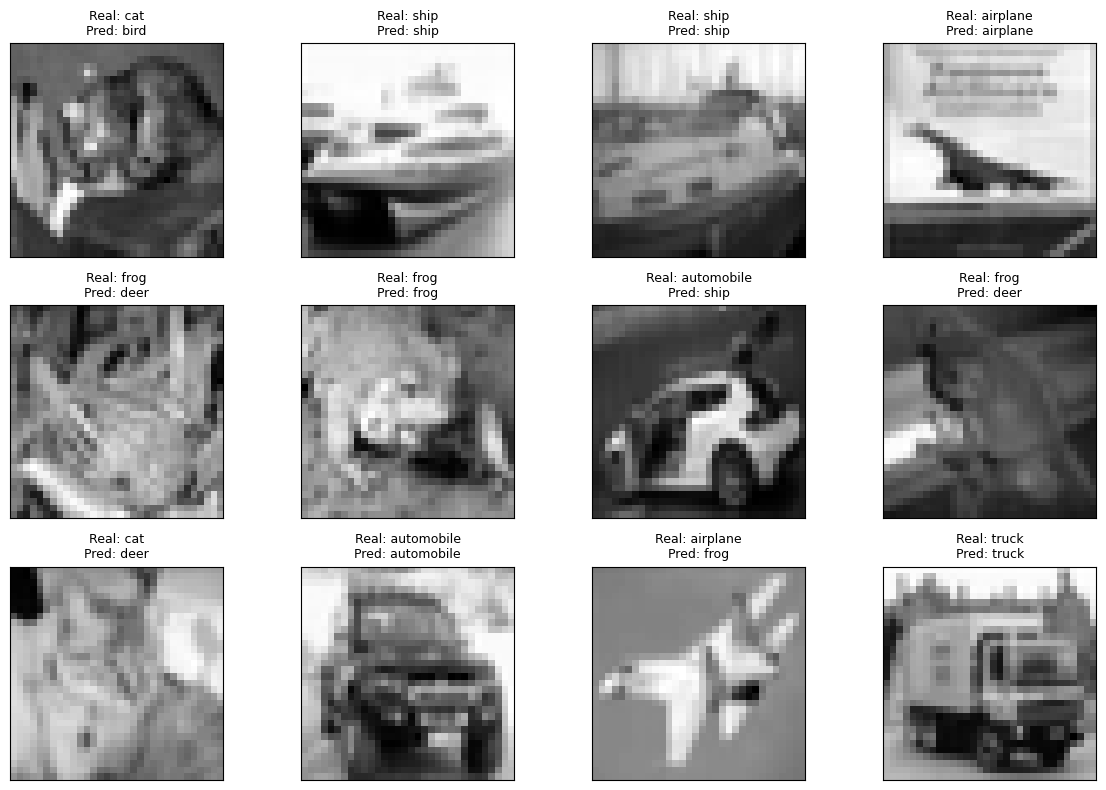

In [16]:
n = 12
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.argmax(logits_batch, axis=1)
predictions = keras.ops.convert_to_numpy(predictions)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = class_names[y_test[i]]
    pred = class_names[predictions[i]]
    plt.title(f"Real: {real}\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 8. Reflexi?n final

### 1. ?Cu?l fue el accuracy final?

**Respuesta:** **36.44%** en el conjunto reportado por `evaluate()`; loss **1.7828**.

### 2. ?Qu? clases parecen m?s dif?ciles de distinguir?

**Respuesta:** En los 12 ejemplos visualizados aparecen confusiones de *frog* con *deer* (dos casos) y de *cat* con *bird* o *deer*. Son observaciones cualitativas de esos ejemplos, no una medici?n de precisi?n por clase.

### 3. Despu?s de `Flatten()`, la imagen se convierte en un vector de 1024 valores. ?Qu? informaci?n importante sobre la imagen podr?a perderse al tratarla ?nicamente como un vector?

**Respuesta:** Se pierde la representaci?n expl?cita de vecindad y posici?n espacial: la capa densa ve p?xeles como posiciones del vector, sin un mecanismo que reconozca patrones locales compartidos como bordes y formas.

### 4. ?Qu? tipo de arquitectura podr?a aprovechar mejor la estructura espacial de las im?genes?

**Respuesta:** Una red neuronal convolucional (CNN), que aplica filtros locales y comparte sus pesos espacialmente.

---

## Para pensar

Nuestro modelo hace:

```text
32?32 ? Flatten ? 1024 valores ? Dense ? ReLU ? Dense(10)
```

Sin embargo, una imagen tiene **estructura espacial**: existen bordes, formas y patrones locales.

Este resultado nos deja preparada la siguiente pregunta del curso:

> **?C?mo puede una red aprovechar directamente la estructura espacial de una imagen?**

La respuesta ser?: **Convolutional Neural Networks (CNNs)**.
